# Building a Movie Recommendation System
## Milestone 1: Ratings as a Matrix
*MATH 344L: Applied Linear Algebra Lab*

We represent movie ratings as a matrix, explore the MovieLens 100K data set, and see why a recommender
system is a linear algebra problem. The missing entries of the matrix are exactly the ratings we want
to predict.

## Part A: A small ratings matrix

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Six people and six movies. The lists give names for the rows and columns; they are not the matrix itself.

In [2]:
movies = ["Action 1", "Action 2", "Action 3",
          "Romance 1", "Romance 2", "Romance 3"]
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]

A number from 1 to 5 is a star rating. `np.nan` ("not a number") marks a movie the person hasn't rated.

In [3]:
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],         # Ana
    [4, np.nan, 5, 2, 1, 1],         # Ben
    [5, 5, np.nan, 1, 2, np.nan],    # Cal
    [1, 2, 1, 5, 4, np.nan],         # Dee
    [np.nan, 1, 2, 4, 5, 5],         # Eve
    [2, 1, np.nan, 5, np.nan, 4],    # Fay
])

This is a $6 \times 6$ matrix: each row is a person from `users` and each column is a movie from
`movies`. A `DataFrame` shows it with those labels.

In [4]:
toy_table = pd.DataFrame(toy, index=users, columns=movies)
toy_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0


In [5]:
missing = np.isnan(toy).sum()
print("Missing entries:", missing, "out of", toy.size)

Missing entries: 8 out of 36


`np.isnan(toy)` gives a True/False matrix with True exactly where a rating is missing, `.sum()` counts
the Trues, and `toy.size` is the total number of entries ($6 \cdot 6 = 36$).

**Make predictions.** Ana, Ben, and Cal like action movies and dislike romance movies; Dee, Eve, and
Fay are the opposite. My guesses for the eight missing ratings are in Exercise 1 below.

## Part B: The MovieLens data
The MovieLens 100K data set has 100,000 movie ratings. Download and unzip it:

In [6]:
import os
import urllib.request
import zipfile

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    zipfile.ZipFile("ml-100k.zip").extractall()

The data folder is **not** uploaded to GitHub. It only lives in Colab's temporary workspace, because
the data license doesn't allow redistribution.

In [7]:
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)
ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


The file is tab-separated, so `sep="\t"` tells pandas a tab separates the columns.

| Column | Meaning |
|---|---|
| `user` | ID number of the person who gave the rating |
| `item` | ID number of the movie |
| `rating` | number of stars, from 1 to 5 |
| `time` | numerical timestamp when the rating was submitted |

Each row is one rating. For example, `user = 196`, `item = 242`, `rating = 3` means user 196 gave
movie 242 three stars. `ratings.head()` just shows the first five rows.

In [8]:
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


100,000 ratings from 943 users for 1,682 movies. `len(ratings)` counts rows, and `.nunique()` counts
distinct values in a column.

In [9]:
star_counts = ratings["rating"].value_counts().sort_index()
star_counts

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

In [10]:
average_rating = ratings["rating"].mean()
print("Average rating:", round(average_rating, 3))

Average rating: 3.53


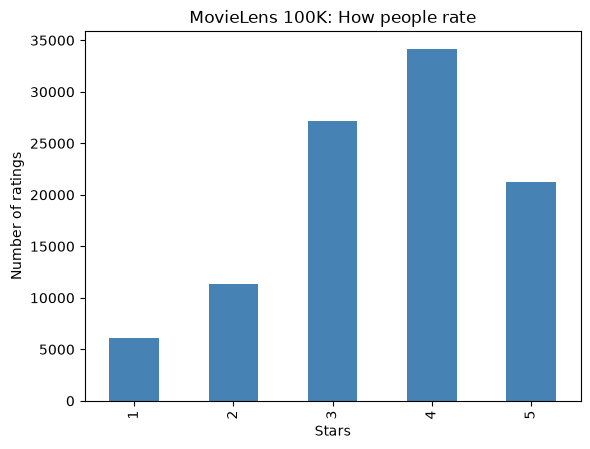

In [11]:
star_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("MovieLens 100K: How people rate")
plt.show()

Ratings of 3 and 4 are the most common, and 1-star ratings are the least common. That makes sense:
people usually choose to watch movies they expect to enjoy.

## Part C: Building the user-by-movie matrix
The raw data has one row per rating. A pivot table reorganizes it into one row per user and one column
per movie.

In [12]:
R = ratings.pivot_table(
    index="user",
    columns="item",
    values="rating"
)

$R_{ij}$ is the rating user $i$ gave movie $j$. If the user hasn't rated that movie, the entry is `NaN`.

In [13]:
print("Matrix shape:", R.shape)

fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing:", round(fraction_missing, 4))

Matrix shape: (943, 1682)
Fraction missing: 0.937


The shape is (943, 1682), and about 93.7% of the entries are missing. `.mean()` on the True/False
array treats True as 1 and False as 0, so it gives the fraction of missing entries.

In [14]:
per_user = ratings.groupby("user").size()

print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


The least active user rated 20 movies, the median user rated 65, and the most active user rated 737.

**Why not take the SVD now?** `np.linalg.svd` needs every entry to be a number, and `R` is full of
`NaN`s. Filling in those missing entries is exactly the recommendation problem we will solve with
low-rank ideas.

## Part D: Which movies are rated most?

In [15]:
titles = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["item", "title"]
)

This file uses `|` as the separator, and `encoding="latin-1"` handles titles with accented characters.
We keep only the movie ID and title.

In [16]:
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])
stats = stats.join(titles.set_index("item"))

top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


`count` is how many ratings a movie got and `mean` is its average rating. *Star Wars (1977)* is the
most rated movie.

## Why a low-rank model is plausible
People don't rate every movie randomly. Their ratings depend on a small number of hidden preferences,
like action vs. romance, comedy vs. drama, new vs. old, or popular vs. unusual. Each user has some
amount of each preference and each movie has some amount of each feature. If only a few of these
factors matter, the whole ratings matrix can be approximated by a low-rank matrix. That's the linear
algebra idea behind a recommendation system.

# Exercises

### Exercise 1 — The eight missing ratings

In [17]:
rows, cols = np.where(np.isnan(toy))
for r, c in zip(rows, cols):
    print(f"{users[r]} - {movies[c]}")

Ana - Romance 2
Ben - Action 2
Cal - Action 3
Cal - Romance 3
Dee - Romance 3
Eve - Action 1
Fay - Action 3
Fay - Romance 2


In [18]:
my_guesses = {
    ("Ana", "Romance 2"): 1,
    ("Ben", "Action 2"): 4,
    ("Cal", "Action 3"): 5,
    ("Cal", "Romance 3"): 1,
    ("Dee", "Romance 3"): 4,
    ("Eve", "Action 1"): 1,
    ("Fay", "Action 3"): 1,
    ("Fay", "Romance 2"): 4,
}

filled = toy_table.copy()
for (user, movie), guess in my_guesses.items():
    filled.loc[user, movie] = guess

filled

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,1.0,2.0
Ben,4.0,4.0,5.0,2.0,1.0,1.0
Cal,5.0,5.0,5.0,1.0,2.0,1.0
Dee,1.0,2.0,1.0,5.0,4.0,4.0
Eve,1.0,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,1.0,5.0,4.0,4.0


My basic idea was to look at what the person usually gives that type of movie, and what the people
with similar taste gave that exact movie.

**Cal – Action 3 → 5.** Cal gave both of the other action movies a 5, so Cal clearly loves action.
Ana and Ben have really similar taste to Cal, and they both gave Action 3 a 5. So a 5 seems like a
pretty safe guess.

**Dee – Romance 3 → 4.** Dee gave the other romance movies a 5 and a 4. Eve and Fay rate movies a lot
like Dee does, and they gave Romance 3 a 5 and a 4. So I'd guess Dee would give it around a 4,
maybe a 5.

### Exercise 2 — A seventh user
Gus likes action movies and doesn't like romance movies. Gus hasn't rated Action 2 or Romance 3.

In [19]:
gus = np.array([5, np.nan, 4, 1, 2, np.nan])

toy7 = np.vstack([toy, gus])
toy7_table = pd.DataFrame(toy7, index=users + ["Gus"], columns=movies)
toy7_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0
Gus,5.0,NaN,4.0,1.0,2.0,NaN


In [20]:
# What did the other action fans give the two movies Gus hasn't rated?
action_fans = toy7_table.loc[["Ana", "Ben", "Cal"], ["Action 2", "Romance 3"]]
print(action_fans)
print()
print("Average from action fans:")
print(action_fans.mean())

     Action 2  Romance 3
Ana       4.0        2.0
Ben       NaN        1.0
Cal       5.0        NaN

Average from action fans:
Action 2     4.5
Romance 3    1.5
dtype: float64


Gus rates like Ana, Ben, and Cal: high for action and low for romance. Those three gave Action 2 about
4.5 stars on average and Romance 3 about 1.5 stars. So I'd predict Gus gives **Action 2 about 4.5**
and **Romance 3 about 1.5**. Basically, Gus would probably love Action 2 and not like Romance 3.

### Exercise 3 — Counting missing entries

In [21]:
print("Missing entries:", np.isnan(toy).sum())
print("Fraction missing:", np.isnan(toy).mean())

Missing entries: 8
Fraction missing: 0.2222222222222222


`np.isnan(toy)` makes a grid of True/False values, with True wherever a rating is missing. Then
`.sum()` adds them up, and since True counts as 1, that gives the number of missing ratings: 8.

To get the *fraction* instead, I used `.mean()` in place of `.sum()`. That's 8 out of 36, about
0.22, so roughly 22% of the toy matrix is missing.

### Exercise 4 — Least common star rating

In [22]:
counts = ratings["rating"].value_counts()

print("Least common rating (stars):", counts.idxmin())
print("Number of times it appears:", counts.min())

Least common rating (stars): 1
Number of times it appears: 6110


The least common rating is **1 star**, which shows up **6,110 times** out of 100,000 ratings. That
matches the bar chart, where the 1-star bar is the shortest.

### Exercise 5 — Average rating for each user

In [23]:
user_avg = ratings.groupby("user")["rating"].agg(["mean", "count"])

user_avg.sort_values("mean", ascending=False).head(5).round(2)

,mean,count
user,,
849,4.87,23
688,4.83,24
507,4.72,58
628,4.70,27
928,4.69,32


In [24]:
top_user = user_avg["mean"].idxmax()
print("Highest average rating: user", top_user)
print("Average:", round(user_avg.loc[top_user, "mean"], 2))
print("Number of movies they rated:", user_avg.loc[top_user, "count"])

Highest average rating: user 849
Average: 4.87
Number of movies they rated: 23


User **849** has the highest average, about **4.87 stars**.

But I wouldn't call them the "most positive" user just from that. They only rated 23 movies, which is
barely above the minimum of 20, so a small number of ratings can make an average look extreme.
Everyone also rated different movies. User 849 might just have watched a bunch of really good movies,
while someone else rated lots of bad ones. And people use the star scale differently, since one
person's 4 might be another person's 5. To really compare how positive people are, we'd want them to
rate the same movies.

### Exercise 6 — `ratings` vs. `R`

In [25]:
print("ratings shape:", ratings.shape)
print("R shape:", R.shape)

ratings shape: (100000, 4)
R shape: (943, 1682)


`ratings` is the raw list. **One row is one rating:** who rated, which movie, how many stars, and
when. It's a long, skinny table with 100,000 rows and only 4 columns.

`R` is the same information rearranged into a matrix. **One row is one user,** and it shows that
person's rating for every one of the 1,682 movies, with `NaN` for movies they didn't rate. It has
943 rows (one per user), and most of it is empty.

So `ratings` lists every rating one by one, while `R` is organized by person and movie, which is the
form we need for linear algebra.

### Exercise 7 — What if nothing were missing?
If every entry of the matrix were filled in, the SVD would work, because `np.linalg.svd` just needs
every entry to be a real number. The only thing stopping us right now is all the `NaN`s.

But that still wouldn't instantly solve the problem. If every rating were already known, there'd be
nothing left to predict, and the real goal is guessing the ratings people *haven't* given yet. Also,
the full SVD just rebuilds the exact same matrix. To find the hidden patterns, we'd have to decide how
many factors to keep and throw away the rest. The SVD also doesn't tell us what each factor means;
we'd have to figure out on our own whether a factor is something like "action vs. romance."

### Exercise 8 — Hidden factors

| Hidden factor | High value for a user | High value for a movie |
|---|---|---|
| **Action level** | Loves explosions, fights, and car chases | Packed with action scenes |
| **Comedy level** | Likes funny, lighthearted movies | A really funny movie |
| **Old vs. new** | Enjoys classic, older films | An older classic (like the 1970s *Star Wars*) |

For example, someone with a high action value would probably rate *Star Wars* high, because that movie
also has a high action value. When a user's tastes line up with a movie's features, the rating tends
to be high, and that's the pattern a low-rank model tries to capture.